# Lab 4 tasks

Name: Khair ul wara Hussain

Student Id: FA23-BAI-022

Course: NLP

---
# NLP Lab Task 04

In [1]:
import re
import time
import random
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

for pkg in ["stopwords", "movie_reviews", "brown", "punkt", "punkt_tab", "vader_lexicon"]:
    nltk.download(pkg, quiet=True)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

## Task 1: Lowercasing Basics and Its Drawbacks

In [2]:
corpus = [
    "Apple released a new phone in the US last week.",
    "I ate an apple and a banana for lunch.",
    "APPLE shares rose sharply after the announcement.",
    "Please tell us what the US government decided.",
    "The manager wants us to visit Apple headquarters.",
    "Bill Gates spoke at the event, and a new bill was passed in the Senate.",
    "March is cold, so we march to school every morning.",
    "Turkey is a beautiful country, but the turkey was delicious.",
    "Python is a popular language, and a python was spotted at the zoo.",
    "WHO announced new guidelines, and nobody knows who wrote them.",
    "IT jobs are growing because it is a booming sector.",
    "He works at Amazon, and the amazon river is huge.",
]

tokenize = lambda s: re.findall(r"[A-Za-z]+", s)
orig = [w for s in corpus for w in tokenize(s)]
low = [w.lower() for w in orig]

print("sentences:", len(corpus))
print("tokens:", len(orig))
print("vocab before lowercasing:", len(set(orig)))
print("vocab after lowercasing :", len(set(low)))

sentences: 12
tokens: 120
vocab before lowercasing: 88
vocab after lowercasing : 77


In [3]:
groups = defaultdict(set)
for w in set(orig):
    groups[w.lower()].add(w)

for k, v in sorted(groups.items()):
    if len(v) > 1:
        print(f"{k:8} <- {sorted(v)}")

amazon   <- ['Amazon', 'amazon']
apple    <- ['APPLE', 'Apple', 'apple']
bill     <- ['Bill', 'bill']
it       <- ['IT', 'it']
march    <- ['March', 'march']
python   <- ['Python', 'python']
the      <- ['The', 'the']
turkey   <- ['Turkey', 'turkey']
us       <- ['US', 'us']
who      <- ['WHO', 'who']


In [4]:
examples = pd.DataFrame({
    "Original": ["US / us", "Apple / apple", "WHO / who"],
    "After lowercasing": ["us", "apple", "who"],
    "Why it is ambiguous": [
        "country (US) vs pronoun (us)",
        "company (Apple) vs fruit (apple)",
        "World Health Organization (WHO) vs question word (who)",
    ],
})
examples

,Original,After lowercasing,Why it is ambiguous
0,US / us,us,country (US) vs pronoun (us)
1,Apple / apple,apple,company (Apple) vs fruit (apple)
2,WHO / who,who,World Health Organization (WHO) vs question word (who)


**Which tasks suffer from lowercasing?**

Named entity recognition is hurt the most, because capitalisation is one of its strongest cues. Once "Apple", "US" or "Turkey" are lowercased, they look the same as the fruit, the pronoun or the bird, and the model loses the signal that marks them as organisations or locations. Sentiment analysis can also lose information, since "GREAT" or "TERRIBLE" in capitals shows stronger emotion than the plain word. Search is affected too: a query for "US" starts matching every "us", and "IT" matches every "it", so many irrelevant documents are returned. On the other hand, lowercasing helps when the case carries no meaning, because it shrinks the vocabulary and reduces data sparsity.

## Task 2: Noise Removal Pipeline

In [5]:
tweets = [
    "@john_doe check this out!!! https://t.co/abc123 #NLP #python 😍😍",
    "<p>Great product, loved it!</p>   Visit www.shop-now.com for  more",
    "Loving the new phone 😂 @techguru   it only costs $100 #bargain",
    "<div class='review'>Worst service ever.</div> http://badservice.com/review?id=22",
    "Learning C++ and Python this semester #coding #CS101 🔥",
    "@sara_k thanks for the e-mail, will reply soon!!!",
    "RT @newsdesk: Breaking news!!! Markets fall 5.5% today https://bit.ly/3xYz #stocks",
    "<b>Amazing</b> battery life,    rating 4.5/5 👍 would buy again",
    "Don't buy this... totally NOT worth it 😡😡 #waste",
    "  Delivered   late   again!!!   @courier_help please fix this #fail  ",
    "<ul><li>Fast shipping</li><li>Good packaging</li></ul> 10/10 recommend",
    "Check https://example.com/deals?ref=tw for 50% off, only $20 today!!",
    "My U.S.A. trip was awesome 😎 #travel #summer2024 @airlines",
    "<a href='http://spam.com'>Click here</a> to win $1000 NOW!!!",
    "The staff were rude and unhelpful :( never coming back #disappointed",
    "Just finished the C# course, next is C++ @udemy #learning 🎓",
]
print(len(tweets))

16


In [6]:
def remove_urls(t):
    return re.sub(r"(https?://|www\.)\S+", " ", t)

def remove_html(t):
    return re.sub(r"<[^>]+>", " ", t)

def remove_mentions(t):
    return re.sub(r"@\w+", " ", t)

def handle_hashtags(t):
    return re.sub(r"#(\w+)", r"\1", t)

def remove_emoji(t):
    return re.sub(r"[\U0001F000-\U0001FAFF\U00002600-\U000027BF\uFE0F]", " ", t)

def remove_punct(t):
    return re.sub(r"[^\w\s]", " ", t)

def fix_spaces(t):
    return re.sub(r"\s+", " ", t).strip()

steps = [remove_html, remove_urls, remove_mentions, handle_hashtags, remove_emoji, remove_punct, fix_spaces]

def clean_text(t, order=steps):
    for f in order:
        t = f(t)
    return t

for t in tweets[:3]:
    print(t)
    print("->", clean_text(t), "\n")

@john_doe check this out!!! https://t.co/abc123 #NLP #python 😍😍
-> check this out NLP python 

<p>Great product, loved it!</p>   Visit www.shop-now.com for  more
-> Great product loved it Visit for more 

Loving the new phone 😂 @techguru   it only costs $100 #bargain
-> Loving the new phone it only costs 100 bargain 



In [7]:
order_b = [remove_punct, remove_html, remove_urls, remove_mentions, handle_hashtags, remove_emoji, fix_spaces]
order_c = [remove_html, remove_urls, handle_hashtags, remove_mentions, remove_emoji, remove_punct, fix_spaces]

a = [clean_text(t) for t in tweets]
b = [clean_text(t, order_b) for t in tweets]
c = [clean_text(t, order_c) for t in tweets]

print("default vs punctuation-first :", sum(x != y for x, y in zip(a, b)), "of", len(tweets), "differ")
print("default vs hashtags-first    :", sum(x != y for x, y in zip(a, c)), "of", len(tweets), "differ")

for i in [0, 1, 3]:
    print("\ndefault :", a[i])
    print("punct 1st:", b[i])

default vs punctuation-first : 13 of 16 differ
default vs hashtags-first    : 0 of 16 differ

default : check this out NLP python
punct 1st: john_doe check this out https t co abc123 NLP python

default : Great product loved it Visit for more
punct 1st: p Great product loved it p Visit www shop now com for more

default : Worst service ever
punct 1st: div class review Worst service ever div http badservice com review id 22


Yes, the order matters. When punctuation is removed first, a URL like `https://t.co/abc123` turns into `https t co abc123` and can no longer be matched by the URL regex, and tags like `<p>` turn into a stray `p`. Mentions with an underscore also survive as words. Swapping the hashtag and mention steps makes no difference here because the two patterns do not overlap. A safe order is: HTML, URLs, mentions, hashtags, emoji, punctuation, and whitespace last.

In [8]:
idx = [4, 2, 6, 5, 12]
comparison = pd.DataFrame({"Before": [tweets[i] for i in idx], "After": [a[i] for i in idx]})
comparison

,Before,After
0,Learning C++ and Python this semester #coding #CS101 🔥,Learning C and Python this semester coding CS101
1,Loving the new phone 😂 @techguru it only costs $100 #bargain,Loving the new phone it only costs 100 bargain
2,RT @newsdesk: Breaking news!!! Markets fall 5.5% today https://bit.ly/3xYz #stocks,RT Breaking news Markets fall 5 5 today stocks
3,"@sara_k thanks for the e-mail, will reply soon!!!",thanks for the e mail will reply soon
4,My U.S.A. trip was awesome 😎 #travel #summer2024 @airlines,My U S A trip was awesome travel summer2024


**Over-cleaning:** the punctuation step is too aggressive. `C++` becomes `C` and is now identical to the language `C`. `$100` loses its currency sign and becomes `100`. `5.5%` turns into `5 5`, `e-mail` into `e mail`, `U.S.A.` into `U S A` and `Don't` into `Don t`. Removing every symbol like this destroys meaning, so a real pipeline should keep a protected list of tokens (C++, C#, prices, percentages) or use a gentler punctuation rule.

## Task 3: Stop-Word Removal and Its Effect on Vocabulary

In [9]:
from nltk.corpus import stopwords, movie_reviews

sw = stopwords.words("english")
print(sw[:20])
print("total stop-words:", len(sw))

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']
total stop-words: 198


In [10]:
random.seed(42)
fids = random.sample(movie_reviews.fileids(), 300)
sents = [[w.lower() for w in s if w.isalpha()] for f in fids for s in movie_reviews.sents(f)]
sents = [s for s in sents if s]

stop = set(sw)
sents_ns = [[w for w in s if w not in stop] for s in sents]

def stats(ss):
    toks = [w for s in ss for w in s]
    return len(toks), len(set(toks)), np.mean([len(s) for s in ss])

before, after = stats(sents), stats(sents_ns)
pd.DataFrame([before, after], index=["before", "after"],
             columns=["tokens", "vocab size", "avg sentence length"]).round(2)

,tokens,vocab size,avg sentence length
before,194852,16868,19.44
after,102708,16720,10.25


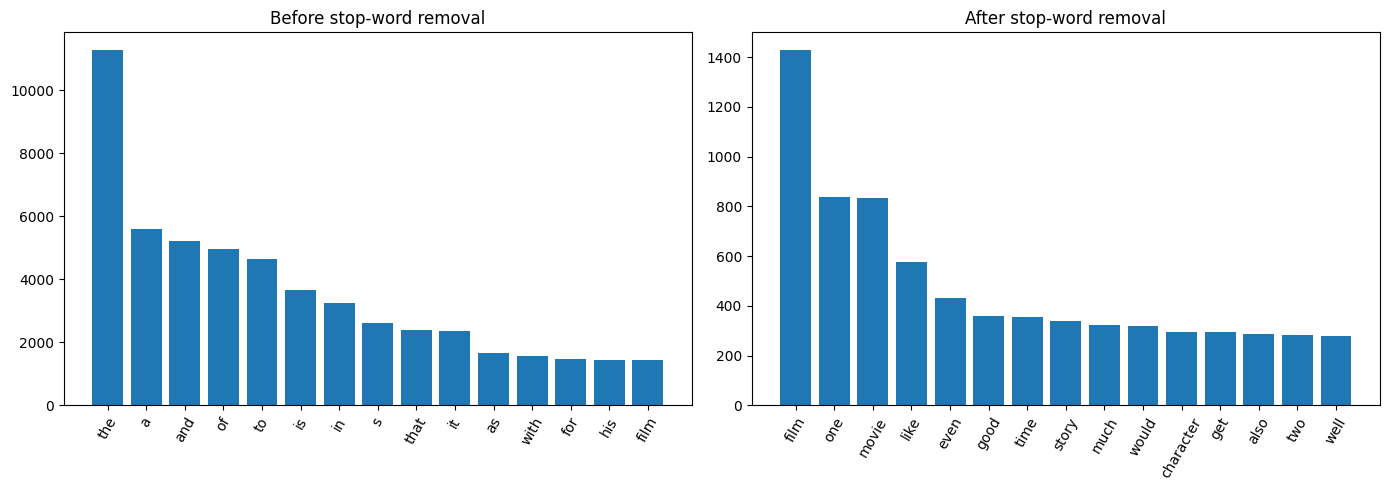

In [11]:
def top15(ss):
    return Counter(w for s in ss for w in s).most_common(15)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a_, ss, title in zip(ax, [sents, sents_ns], ["Before stop-word removal", "After stop-word removal"]):
    words, counts = zip(*top15(ss))
    a_.bar(words, counts)
    a_.set_title(title)
    a_.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

In [12]:
add = {
    "film": "appears in almost every review, so it carries no information",
    "movie": "same as film, a domain-level filler word",
    "films": "plural form of film",
    "movies": "plural form of movie",
    "one": "very frequent ('one of the best', 'no one') with little meaning",
    "would": "modal verb that is not in the default list but is very frequent",
    "also": "connector word that does not help in classification",
    "even": "filler word that is very common in reviews",
}
remove = {
    "not": "negation, needed to keep the sentiment correct",
    "no": "negation, 'no good' is very different from 'good'",
    "nor": "negation word",
    "very": "intensifier, 'very good' vs 'good'",
    "too": "intensifier, 'too long' is a complaint",
    "against": "can show opposition or criticism",
}

custom = (set(sw) | set(add)) - set(remove)
print("added  :", len(add), "| removed:", len(remove))
print("custom list size:", len(custom))

pd.DataFrame({"word": list(add) + list(remove),
              "action": ["added"] * len(add) + ["removed"] * len(remove),
              "justification": list(add.values()) + list(remove.values())})

added  : 8 | removed: 6
custom list size: 200


,word,action,justification
0,film,added,"appears in almost every review, so it carries no information"
1,movie,added,"same as film, a domain-level filler word"
2,films,added,plural form of film
3,movies,added,plural form of movie
4,one,added,"very frequent ('one of the best', 'no one') with little meaning"
5,would,added,modal verb that is not in the default list but is very frequent
6,also,added,connector word that does not help in classification
7,even,added,filler word that is very common in reviews
8,not,removed,"negation, needed to keep the sentiment correct"
9,no,removed,"negation, 'no good' is very different from 'good'"


In [13]:
sents_c = [[w for w in s if w not in custom] for s in sents]
pd.DataFrame([stats(sents), stats(sents_ns), stats(sents_c)], index=["no removal", "nltk list", "custom list"],
             columns=["tokens", "vocab size", "avg sentence length"]).round(2)

,tokens,vocab size,avg sentence length
no removal,194852,16868,19.44
nltk list,102708,16720,10.25
custom list,99995,16718,9.98


**Observation:** stop-word removal cut the token count roughly in half (194,852 to 102,708) and the average sentence length from 19.4 to 10.3, but the vocabulary shrank by only about 150 words. The list has just 198 entries, yet they cover almost half of all tokens. Before removal the top-15 chart is all function words (the, a, and, of, to), while after removal content words such as film, one, movie and good take over. The custom list removes a few more domain words and keeps the negations in the text.

## Task 4: Risks of Stop-Word Removal (Sentiment, MT, Chatbots)

### 4.1 Sentiment

In [14]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

def remove_sw(text, stopset=stop):
    return " ".join(w for w in re.findall(r"[a-z']+", text.lower()) if w not in stopset)

def label(text):
    c = sia.polarity_scores(text)["compound"]
    return "pos" if c >= 0.05 else "neg" if c <= -0.05 else "neu"

neg_sents = [
    "The food was not good",
    "I am never happy with this service",
    "This is not bad at all",
    "There is no problem with the delivery",
    "I do not like this phone",
]

rows = []
for s in neg_sents:
    r = remove_sw(s)
    rows.append([s, r, sia.polarity_scores(s)["compound"], sia.polarity_scores(r)["compound"], label(s), label(r)])

sent_df = pd.DataFrame(rows, columns=["Original", "After removal", "score before", "score after", "label before", "label after"])
sent_df["flipped"] = sent_df["label before"] != sent_df["label after"]
sent_df

,Original,After removal,score before,score after,label before,label after,flipped
0,The food was not good,food good,-0.3412,0.4404,neg,pos,True
1,I am never happy with this service,never happy service,-0.4585,-0.4585,neg,neg,False
2,This is not bad at all,bad,0.4310,-0.5423,pos,neg,True
3,There is no problem with the delivery,problem delivery,-0.5994,-0.4019,neg,neg,False
4,I do not like this phone,like phone,-0.2755,0.3612,neg,pos,True


Three of the five sentences change polarity after normal stop-word removal: "not good" becomes "food good", "not bad" becomes "bad" and "do not like" becomes "like phone". "never" is not in NLTK's list, so that sentence survives, and VADER already scores "no problem" as negative, so those two show no flip even though the second one is positive for a human reader.

### 4.2 Machine Translation

In [15]:
mt_sents = [
    "I do not want to go to the market today.",
    "The teacher was not happy with the results of the exam.",
    "She is going to the hospital because her mother is sick.",
]

urdu_original = [
    "میں آج بازار نہیں جانا چاہتا۔",
    "استاد امتحان کے نتائج سے خوش نہیں تھے۔",
    "وہ ہسپتال جا رہی ہے کیونکہ اس کی ماں بیمار ہے۔",
]
urdu_reduced = [
    "میں آج بازار جانا چاہتا ہوں۔",
    "استاد خوش نتائج امتحان۔",
    "ہسپتال جاتے ہوئے ماں بیمار۔",
]
notes = [
    "negation lost, meaning is reversed",
    "negation lost, no tense, sentence is broken",
    "reason (because) and subject lost, only keywords remain",
]

pd.DataFrame({
    "English": mt_sents,
    "Reduced": [remove_sw(s) for s in mt_sents],
    "Urdu (original)": urdu_original,
    "Urdu (reduced)": urdu_reduced,
    "Effect": notes,
})

,English,Reduced,Urdu (original),Urdu (reduced),Effect
0,I do not want to go to the market today.,want go market today,میں آج بازار نہیں جانا چاہتا۔,میں آج بازار جانا چاہتا ہوں۔,"negation lost, meaning is reversed"
1,The teacher was not happy with the results of the exam.,teacher happy results exam,استاد امتحان کے نتائج سے خوش نہیں تھے۔,استاد خوش نتائج امتحان۔,"negation lost, no tense, sentence is broken"
2,She is going to the hospital because her mother is sick.,going hospital mother sick,وہ ہسپتال جا رہی ہے کیونکہ اس کی ماں بیمار ہے۔,ہسپتال جاتے ہوئے ماں بیمار۔,"reason (because) and subject lost, only keywords remain"


Removing the stop-words also removes "not" from the first two sentences, so the Urdu translation of the reduced text says the opposite or turns into a broken fragment. In the third sentence the "because" link between the two events is lost. In all three cases the meaning is distorted.

### 4.3 Chatbot intent

In [16]:
queries = [
    "How to not be charged?",
    "What is the status of my order?",
    "I am not able to log in to my account",
    "Who is responsible for my refund?",
    "What is the difference between the basic and the premium plan?",
]
damage = [
    "intent flips: now looks like 'I was charged'",
    "mostly survives, but the question form is gone",
    "reads as 'able log', meaning the login problem is lost",
    "the question about responsibility is lost",
    "relation between the two plans (between, and) is lost",
]

pd.DataFrame({"Query": queries, "After removal": [remove_sw(q) for q in queries], "Damage": damage})

,Query,After removal,Damage
0,How to not be charged?,charged,intent flips: now looks like 'I was charged'
1,What is the status of my order?,status order,"mostly survives, but the question form is gone"
2,I am not able to log in to my account,able log account,"reads as 'able log', meaning the login problem is lost"
3,Who is responsible for my refund?,responsible refund,the question about responsibility is lost
4,What is the difference between the basic and the premium plan?,difference basic premium plan,"relation between the two plans (between, and) is lost"


Negation words and question words carry the intent of a query. Without them "How to not be charged?" looks like a billing complaint, and "I am not able to log in" turns into a list of keywords.

### 4.4 A safer strategy

In [17]:
negations = {"no", "not", "nor", "never", "none", "nobody", "nothing", "neither", "nowhere", "without", "cannot"}
negations |= {w for w in stop if "n't" in w}
safe_stop = stop - negations

rows = []
for s in neg_sents:
    n, f = remove_sw(s), remove_sw(s, safe_stop)
    rows.append([s, n, f, label(s), label(n), label(f)])

safe_df = pd.DataFrame(rows, columns=["Original", "Naive removal", "Safe removal", "orig label", "naive label", "safe label"])
safe_df["naive ok"] = safe_df["orig label"] == safe_df["naive label"]
safe_df["safe ok"] = safe_df["orig label"] == safe_df["safe label"]
safe_df

,Original,Naive removal,Safe removal,orig label,naive label,safe label,naive ok,safe ok
0,The food was not good,food good,food not good,neg,pos,neg,False,True
1,I am never happy with this service,never happy service,never happy service,neg,neg,neg,True,True
2,This is not bad at all,bad,not bad,pos,neg,pos,False,True
3,There is no problem with the delivery,problem delivery,no problem delivery,neg,neg,neg,True,True
4,I do not like this phone,like phone,not like phone,neg,pos,neg,False,True


Keeping the negation words fixes all three flipped sentences, and the label now matches the original for every sentence. The cost is a slightly larger vocabulary, which is a small price compared to a wrong sentiment.

## Task 5: Hands-On with the Porter Stemmer

In [18]:
from nltk.stem import PorterStemmer, SnowballStemmer

ps = PorterStemmer()
sb = SnowballStemmer("english")

words = ["running", "runs", "ran", "studies", "studying", "happily", "happiness", "generalization",
         "general", "generous", "better", "was", "were", "cars", "geese", "mice", "university",
         "universe", "organization", "organ", "argue", "argument", "fairly", "easily", "flies",
         "computing", "computer", "computational", "agreement", "operate", "operation", "wolves",
         "swam", "leaves", "caring", "data"]

verdict = {
    "running": "Correct", "runs": "Correct", "ran": "Incorrect", "studies": "Correct", "studying": "Correct",
    "happily": "Incorrect", "happiness": "Correct", "generalization": "Incorrect", "general": "Incorrect",
    "generous": "Incorrect", "better": "Incorrect", "was": "Incorrect", "were": "Incorrect", "cars": "Correct",
    "geese": "Incorrect", "mice": "Incorrect", "university": "Incorrect", "universe": "Incorrect",
    "organization": "Incorrect", "organ": "Correct", "argue": "Correct", "argument": "Incorrect",
    "fairly": "Incorrect", "easily": "Incorrect", "flies": "Correct", "computing": "Correct",
    "computer": "Correct", "computational": "Correct", "agreement": "Incorrect", "operate": "Correct",
    "operation": "Correct", "wolves": "Correct", "swam": "Incorrect", "leaves": "Correct",
    "caring": "Correct", "data": "Correct",
}

table = pd.DataFrame({"Word": words, "Stem": [ps.stem(w) for w in words], "Verdict": [verdict[w] for w in words]})
print(len(words), "words,", (table.Verdict == "Correct").sum(), "correct")
table

36 words, 18 correct


,Word,Stem,Verdict
0,running,run,Correct
1,runs,run,Correct
2,ran,ran,Incorrect
3,studies,studi,Correct
4,studying,studi,Correct
5,happily,happili,Incorrect
6,happiness,happi,Correct
7,generalization,gener,Incorrect
8,general,gener,Incorrect
9,generous,gener,Incorrect


In [19]:
over = [("university", "universe"), ("organization", "organ"), ("general", "generous"), ("generalization", "generous")]
under = [("ran", "run"), ("better", "good"), ("was", "be"), ("argument", "argue"), ("happily", "happy"), ("geese", "goose")]

def pair_table(pairs):
    return pd.DataFrame([(a, b, ps.stem(a), ps.stem(b), ps.stem(a) == ps.stem(b)) for a, b in pairs],
                        columns=["word 1", "word 2", "stem 1", "stem 2", "same stem"])

print("over-stemming (different meanings, same stem)")
display(pair_table(over))
print("under-stemming (related words, different stems)")
display(pair_table(under))

over-stemming (different meanings, same stem)


,word 1,word 2,stem 1,stem 2,same stem
0,university,universe,univers,univers,True
1,organization,organ,organ,organ,True
2,general,generous,gener,gener,True
3,generalization,generous,gener,gener,True


under-stemming (related words, different stems)


,word 1,word 2,stem 1,stem 2,same stem
0,ran,run,ran,run,False
1,better,good,better,good,False
2,was,be,wa,be,False
3,argument,argue,argument,argu,False
4,happily,happy,happili,happi,False
5,geese,goose,gees,goos,False


In [20]:
extra = ["fairly", "generously", "skies", "bigger", "dying", "singing", "happily", "easily"]
diff = [(w, ps.stem(w), sb.stem(w)) for w in dict.fromkeys(words + extra) if ps.stem(w) != sb.stem(w)]
print(len(diff), "words differ")
pd.DataFrame(diff, columns=["Word", "Porter", "Snowball"])

6 words differ


,Word,Porter,Snowball
0,generalization,gener,general
1,general,gener,general
2,generous,gener,generous
3,was,wa,was
4,fairly,fairli,fair
5,generously,gener,generous


Under my own judgement Porter got 18 of the 36 words right. Over-stemming: university/universe share `univers`, organization/organ share `organ`, and general/generous share `gener`. Under-stemming: ran/run, was/be, better/good, argument/argue and happily/happy all end up with different stems, because Porter only strips suffixes and cannot handle irregular forms. Snowball differs from Porter on 6 words (generalization, general, generous, generously, was, fairly); it handles `fairly` and `generous` better, but it still has the same weakness on irregular words.

## Task 6: Lemmatization (spaCy) vs. Stemming

In [21]:
import spacy

nlp = spacy.load("en_core_web_sm")

text = ("The students were studying hard for their exams, and the teacher said that the results were better "
        "than expected. She was running late because the buses had stopped, so the children walked home "
        "through the crowded streets. Many of them were talking about the mice that had been found in the "
        "old library, and others discussed the best movies they had watched during the holidays. The "
        "principal believed that the new programs would improve learning, and he thanked the teachers who "
        "had worked tirelessly. After the meeting, the staff members made plans for the upcoming events, "
        "while the parents were happily waiting outside. Everyone agreed that studies show that better "
        "schools create happier communities.")

doc = nlp(text)
print("words:", len(text.split()), "| spaCy tokens:", len(doc))

words: 114 | spaCy tokens: 126


In [22]:
rows = [(t.text, t.pos_, ps.stem(t.text), t.lemma_) for t in doc if t.is_alpha]
comp = pd.DataFrame(rows, columns=["Token", "POS", "Stem", "Lemma"])
comp.head(30)

,Token,POS,Stem,Lemma
0,The,DET,the,the
1,students,NOUN,student,student
2,were,AUX,were,be
3,studying,VERB,studi,study
4,hard,ADV,hard,hard
5,for,ADP,for,for
6,their,PRON,their,their
7,exams,NOUN,exam,exam
8,and,CCONJ,and,and
9,the,DET,the,the


In [23]:
better = comp[(comp.Token.str.lower() != comp.Lemma.str.lower()) & (comp.Stem != comp.Lemma.str.lower())]
better.drop_duplicates().head(25)

,Token,POS,Stem,Lemma
2,were,AUX,were,be
3,studying,VERB,studi,study
11,said,VERB,said,say
16,better,ADJ,better,well
20,was,AUX,wa,be
25,buses,NOUN,buse,bus
26,had,AUX,had,have
30,children,NOUN,children,child
39,them,PRON,them,they
44,mice,NOUN,mice,mouse


In [24]:
for s in ["The results were better than expected.", "She sings better than him.", "I saw the bird.", "He cut the wood with a saw.",
          "We are meeting at noon.", "The meeting ended early."]:
    print(s, "->", [(t.text, t.pos_, t.lemma_) for t in nlp(s) if t.text.lower() in ("better", "saw", "meeting")])

The results were better than expected. -> [('better', 'ADJ', 'well')]
She sings better than him. -> [('better', 'ADV', 'well')]
I saw the bird. -> [('saw', 'VERB', 'see')]
He cut the wood with a saw. -> [('saw', 'NOUN', 'saw')]
We are meeting at noon. -> [('meeting', 'VERB', 'meet')]
The meeting ended early. -> [('meeting', 'NOUN', 'meeting')]


In [25]:
def stem_all(t):
    return [ps.stem(w) for w in re.findall(r"\w+", t)]

def lemma_all(t):
    return [tok.lemma_ for tok in nlp(t)]

n = 200
t0 = time.perf_counter()
for _ in range(n):
    stem_all(text)
t_stem = time.perf_counter() - t0

t0 = time.perf_counter()
for _ in range(n):
    lemma_all(text)
t_lem = time.perf_counter() - t0

print(f"stemming      : {t_stem / n * 1000:.2f} ms per paragraph")
print(f"lemmatization : {t_lem / n * 1000:.2f} ms per paragraph")
print(f"stemming is about {t_lem / t_stem:.0f}x faster")

stemming      : 1.27 ms per paragraph
lemmatization : 15.11 ms per paragraph
stemming is about 12x faster


Lemmatization returns real words (studying -> study, mice -> mouse, children -> child, were/was -> be), while the stemmer gives forms like `studi`, `movi`, `commun` and `wa`. The POS tag decides the lemma: "saw" becomes `see` as a verb but stays `saw` as a noun, and "meeting" becomes `meet` only when it is a verb. Note that spaCy's small model maps "better" to `well` (and "best" to `good`) rather than `good`. Stemming was about an order of magnitude faster here because it needs no tagger. I would use stemming for search or indexing over large amounts of text where speed matters and the stem is never shown, and lemmatization when real words are needed, such as chatbots, NER or reading the vocabulary.

## Task 7: Preprocessing Pipeline

In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split

nlp_fast = spacy.load("en_core_web_sm", disable=["parser", "ner"])

class Preprocessor:
    def __init__(self, lower=True, noise=True, stop=False, stem=False, lemma=False):
        self.lower, self.noise, self.stop, self.stem, self.lemma = lower, noise, stop, stem, lemma
        self.stopset = set(stopwords.words("english"))
        self.stemmer = PorterStemmer()

    def tokens(self, text):
        if self.lower:
            text = text.lower()
        if self.noise:
            text = re.sub(r"<[^>]+>|https?://\S+", " ", text)
            text = re.sub(r"[^A-Za-z\s]", " ", text)
        toks = text.split()
        if self.stop:
            toks = [w for w in toks if w.lower() not in self.stopset]
        if self.stem:
            toks = [self.stemmer.stem(w) for w in toks]
        return toks

    def transform(self, docs):
        out = [self.tokens(d) for d in docs]
        if self.lemma:
            texts = [" ".join(t) for t in out]
            out = [[tok.lemma_ for tok in d] for d in nlp_fast.pipe(texts, batch_size=20)]
        return out

In [27]:
random.seed(7)
pos = random.sample(movie_reviews.fileids("pos"), 250)
neg = random.sample(movie_reviews.fileids("neg"), 250)
docs = [movie_reviews.raw(f) for f in pos + neg]
y = np.array([1] * len(pos) + [0] * len(neg))
print(len(docs), "documents")

configs = {
    "lowercase only": dict(),
    "lowercase + stop-words": dict(stop=True),
    "lowercase + stemming": dict(stem=True),
    "lowercase + lemmatization": dict(lemma=True),
}

processed = {}
for name, cfg in configs.items():
    processed[name] = Preprocessor(**cfg).transform(docs)

summary = pd.DataFrame({
    name: {"vocabulary size": len({w for d in p for w in d}), "avg tokens per doc": np.mean([len(d) for d in p])}
    for name, p in processed.items()
}).T
summary.round(1)

500 documents


,vocabulary size,avg tokens per doc
lowercase only,21297.0,649.8
lowercase + stop-words,21148.0,342.9
lowercase + stemming,14548.0,649.8
lowercase + lemmatization,17032.0,649.9


In [28]:
skf = StratifiedKFold(5, shuffle=True, random_state=1)
res = {}
for name, p in processed.items():
    x = [" ".join(d) for d in p]
    model = make_pipeline(TfidfVectorizer(token_pattern=r"\S+"), LogisticRegression(max_iter=1000))
    cv = cross_val_score(model, x, y, cv=skf)
    xtr, xte, ytr, yte = train_test_split(x, y, test_size=0.25, stratify=y, random_state=1)
    test = model.fit(xtr, ytr).score(xte, yte)
    res[name] = {"CV accuracy": cv.mean(), "test accuracy": test}

acc = pd.DataFrame(res).T
acc.round(4)

,CV accuracy,test accuracy
lowercase only,0.732,0.736
lowercase + stop-words,0.764,0.760
lowercase + stemming,0.738,0.752
lowercase + lemmatization,0.722,0.720


**Analysis:** lowercase + stop-word removal gave the best accuracy (CV 0.764, test 0.760), ahead of stemming (0.738), the lowercase-only baseline (0.732) and lemmatization (0.722). Stop-word removal halved the tokens per document while barely touching the vocabulary, and it helps TF-IDF because the most frequent words carry no sentiment. Stemming cut the vocabulary from 21,297 to 14,548 and gave a small gain, since related word forms now share one feature. Lemmatization reduced the vocabulary less and was slightly below the baseline, probably because the tagger works worse on lowercased text without punctuation. The differences are only 1 to 4 points on 500 documents, so they could change with another sample, but the stop-word gain is the most consistent across both CV and the test split.

## Task 8: Implementing Minimum Edit Distance (Levenshtein)

In [29]:
calls = 0

def lev_rec(a, b):
    global calls
    calls += 1
    if not a:
        return len(b)
    if not b:
        return len(a)
    if a[-1] == b[-1]:
        return lev_rec(a[:-1], b[:-1])
    return 1 + min(lev_rec(a[:-1], b), lev_rec(a, b[:-1]), lev_rec(a[:-1], b[:-1]))

print(lev_rec("kitten", "sitting"))

rows = []
for n in range(3, 9):
    calls = 0
    t0 = time.perf_counter()
    lev_rec("a" * n, "b" * n)
    rows.append((n, calls, round(time.perf_counter() - t0, 4)))
pd.DataFrame(rows, columns=["string length", "recursive calls", "seconds"])

3


,string length,recursive calls,seconds
0,3,94,0.0000
1,4,481,0.0001
2,5,2524,0.0005
3,6,13483,0.0024
4,7,72958,0.0127
5,8,398593,0.0701


The recursive version recomputes the same sub-problems again and again, because `lev_rec(a[:i], b[:j])` is reached through many different paths. The number of calls grows exponentially with the string length, so it becomes unusable even for words of about 12 characters. Dynamic programming stores each sub-problem once and needs only O(m x n) time.

In [30]:
def lev_table(a, b, sub=1):
    m, n = len(a), len(b)
    d = np.zeros((m + 1, n + 1), dtype=int)
    d[:, 0] = np.arange(m + 1)
    d[0, :] = np.arange(n + 1)
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            cost = 0 if a[i - 1] == b[j - 1] else sub
            d[i, j] = min(d[i - 1, j] + 1, d[i, j - 1] + 1, d[i - 1, j - 1] + cost)
    return d

def show(a, b, sub=1):
    d = lev_table(a, b, sub)
    return pd.DataFrame(d, index=["#"] + list(a), columns=["#"] + list(b))

pairs = [("intention", "execution"), ("kitten", "sitting"), ("sunday", "saturday")]
for a, b in pairs:
    print(f"{a} -> {b}  (distance = {lev_table(a, b)[-1, -1]})")
    display(show(a, b))

intention -> execution  (distance = 5)


,#,e,x,e,c,u,t,i,o,n
#,0,1,2,3,4,5,6,7,8,9
i,1,1,2,3,4,5,6,6,7,8
n,2,2,2,3,4,5,6,7,7,7
t,3,3,3,3,4,5,5,6,7,8
e,4,3,4,3,4,5,6,6,7,8
n,5,4,4,4,4,5,6,7,7,7
t,6,5,5,5,5,5,5,6,7,8
i,7,6,6,6,6,6,6,5,6,7
o,8,7,7,7,7,7,7,6,5,6
n,9,8,8,8,8,8,8,7,6,5


kitten -> sitting  (distance = 3)


,#,s,i,t,t,i,n,g
#,0,1,2,3,4,5,6,7
k,1,1,2,3,4,5,6,7
i,2,2,1,2,3,4,5,6
t,3,3,2,1,2,3,4,5
t,4,4,3,2,1,2,3,4
e,5,5,4,3,2,2,3,4
n,6,6,5,4,3,3,2,3


sunday -> saturday  (distance = 3)


,#,s,a,t,u,r,d,a,y
#,0,1,2,3,4,5,6,7,8
s,1,0,1,2,3,4,5,6,7
u,2,1,1,2,2,3,4,5,6
n,3,2,2,2,3,3,4,5,6
d,4,3,3,3,3,4,3,4,5
a,5,4,3,4,4,4,4,3,4
y,6,5,4,4,5,5,5,4,3


In [31]:
def backtrace(a, b, sub=1):
    d = lev_table(a, b, sub)
    i, j = len(a), len(b)
    ops = []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and a[i - 1] == b[j - 1] and d[i, j] == d[i - 1, j - 1]:
            ops.append(f"keep '{a[i - 1]}'")
            i, j = i - 1, j - 1
        elif i > 0 and j > 0 and d[i, j] == d[i - 1, j - 1] + sub:
            ops.append(f"substitute '{a[i - 1]}' -> '{b[j - 1]}'")
            i, j = i - 1, j - 1
        elif i > 0 and d[i, j] == d[i - 1, j] + 1:
            ops.append(f"delete '{a[i - 1]}'")
            i -= 1
        else:
            ops.append(f"insert '{b[j - 1]}'")
            j -= 1
    return d[-1, -1], ops[::-1]

for a, b in pairs:
    for sub in (1, 2):
        dist, ops = backtrace(a, b, sub)
        print(f"{a} -> {b} | substitution cost {sub} | distance {dist}")
        print("   ", [o for o in ops if not o.startswith("keep")])

intention -> execution | substitution cost 1 | distance 5
    ["substitute 'i' -> 'e'", "substitute 'n' -> 'x'", "substitute 't' -> 'e'", "substitute 'e' -> 'c'", "substitute 'n' -> 'u'"]
intention -> execution | substitution cost 2 | distance 8
    ["delete 'i'", "substitute 'n' -> 'e'", "substitute 't' -> 'x'", "insert 'c'", "substitute 'n' -> 'u'"]
kitten -> sitting | substitution cost 1 | distance 3
    ["substitute 'k' -> 's'", "substitute 'e' -> 'i'", "insert 'g'"]
kitten -> sitting | substitution cost 2 | distance 5
    ["substitute 'k' -> 's'", "substitute 'e' -> 'i'", "insert 'g'"]
sunday -> saturday | substitution cost 1 | distance 3
    ["insert 'a'", "insert 't'", "substitute 'n' -> 'r'"]
sunday -> saturday | substitution cost 2 | distance 4
    ["insert 'a'", "insert 't'", "substitute 'n' -> 'r'"]


In [32]:
pd.DataFrame([(a, b, lev_table(a, b)[-1, -1], lev_table(a, b, 2)[-1, -1]) for a, b in pairs],
             columns=["word 1", "word 2", "sub cost 1", "sub cost 2"])

,word 1,word 2,sub cost 1,sub cost 2
0,intention,execution,5,8
1,kitten,sitting,3,5
2,sunday,saturday,3,4


The DP tables give 5 for intention/execution, 3 for kitten/sitting and 3 for sunday/saturday. With substitution cost 2 the distances become 8, 5 and 4, because a substitution now costs the same as a deletion plus an insertion. The edit path stays the same for kitten/sitting and sunday/saturday, but for intention/execution the backtrace switches to using a delete and an insert.

## Task 9: Spelling Correction with Edit Distance

In [33]:
from nltk.corpus import brown
from functools import lru_cache

freq = Counter(w.lower() for w in brown.words() if w.isalpha())
vocab = sorted(w for w, _ in freq.most_common(10000))
print("dictionary size:", len(vocab))
print(vocab[:10])

dictionary size: 10000
['a', 'aaron', 'abandon', 'abandoned', 'abandoning', 'abandonment', 'abbey', 'abel', 'abide', 'abilities']


In [34]:
def lev(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

@lru_cache(maxsize=None)
def distances(word):
    return [(lev(word, w), w) for w in vocab]

def suggest(word, k=5):
    ranked = sorted(distances(word), key=lambda x: x[0])
    return [w for _, w in ranked[:k]]

print(suggest("recieve"))
print(suggest("definately"))

['relieve', 'believe', 'receive', 'recipe', 'relieved']


['definitely', 'definite', 'adequately', 'dedicated', 'defeated']


In [35]:
tests = {
    "recieve": "receive", "definately": "definitely", "acommodate": "accommodate", "seperate": "separate",
    "occured": "occurred", "untill": "until", "wich": "which", "beleive": "believe", "goverment": "government",
    "enviroment": "environment", "tommorow": "tomorrow", "freind": "friend", "adress": "address",
    "neccessary": "necessary", "wierd": "weird", "begining": "beginning", "truely": "truly",
    "thier": "their", "calender": "calendar", "sucess": "success",
}
print("misspellings that are already in the dictionary:", [w for w in tests if w in vocab])
print("targets missing from the dictionary:", [w for w in tests.values() if w not in vocab])

misspellings that are already in the dictionary: []
targets missing from the dictionary: []


In [36]:
rows = [(m, c, suggest(m)[0], suggest(m)[0] == c) for m, c in tests.items()]
base = pd.DataFrame(rows, columns=["Misspelled", "Correct", "Top-1", "Hit"])
print("Top-1 accuracy:", base.Hit.mean())
base

Top-1 accuracy: 0.75


,Misspelled,Correct,Top-1,Hit
0,recieve,receive,relieve,False
1,definately,definitely,definitely,True
2,acommodate,accommodate,accommodate,True
3,seperate,separate,separate,True
4,occured,occurred,occurred,True
5,untill,until,until,True
6,wich,which,rich,False
7,beleive,believe,believe,True
8,goverment,government,government,True
9,enviroment,environment,environment,True


In [37]:
def suggest_freq(word, k=5):
    ranked = sorted(distances(word), key=lambda x: (x[0], -freq[x[1]]))
    return [w for _, w in ranked[:k]]

rows = []
for m, c in tests.items():
    s1, s2 = suggest(m), suggest_freq(m)
    rows.append((m, c, s1[0], s2[0], s2[:3], s1[0] == c, s2[0] == c))
cmp_df = pd.DataFrame(rows, columns=["Misspelled", "Correct", "Plain top-1", "Freq top-1", "Freq top-3", "Plain hit", "Freq hit"])

print("plain Levenshtein   :", cmp_df["Plain hit"].mean())
print("with frequency ties :", cmp_df["Freq hit"].mean())
cmp_df

plain Levenshtein   : 0.75
with frequency ties : 0.75


,Misspelled,Correct,Plain top-1,Freq top-1,Freq top-3,Plain hit,Freq hit
0,recieve,receive,relieve,relieve,"[relieve, believe, receive]",False,False
1,definately,definitely,definitely,definitely,"[definitely, definite, finally]",True,True
2,acommodate,accommodate,accommodate,accommodate,"[accommodate, commodity, commodities]",True,True
3,seperate,separate,separate,separate,"[separate, operate, separated]",True,True
4,occured,occurred,occurred,occurred,"[occurred, occur, occupied]",True,True
5,untill,until,until,until,"[until, still, till]",True,True
6,wich,which,rich,with,"[with, which, wish]",False,False
7,beleive,believe,believe,believe,"[believe, receive, leave]",True,True
8,goverment,government,government,government,"[government, movement, governments]",True,True
9,enviroment,environment,environment,environment,"[environment, government, equipment]",True,True


In [38]:
def topk(f, k):
    return np.mean([c in f(m, k) for m, c in tests.items()])

pd.DataFrame({"plain": [topk(suggest, k) for k in (1, 3, 5)],
              "with frequency": [topk(suggest_freq, k) for k in (1, 3, 5)]}, index=["top-1", "top-3", "top-5"])

,plain,with frequency
top-1,0.75,0.75
top-3,0.85,0.90
top-5,0.90,0.90


In [39]:
for w in ["their", "there", "to", "too"]:
    print(w, "in dictionary:", w in vocab, "| distance to itself:", min(distances(w))[0])

their in dictionary: True | distance to itself: 0
there in dictionary: True | distance to itself: 0
to in dictionary: True | distance to itself: 0
too in dictionary: True | distance to itself: 0


Plain edit distance gets 15 of 20 right at top-1 (0.75). Breaking ties with word frequency does not change top-1 here, but top-3 accuracy goes from 0.85 to 0.90: for "freind" the word `friend` moves from fifth place to second. The remaining top-1 errors are words that are as close or closer than the target: "recieve" is two edits from `receive` (a swap counts as two) but only one from `relieve`, "freind" is one edit from `find`, and "thier" is one from `thief`. Damerau-Levenshtein, where a transposition costs one, would fix several of these. Real-word errors such as "their/there" are never caught, because the typed word is already in the dictionary at distance 0, so nothing looks wrong. Catching them needs context, for example an n-gram or neural language model.